# 01 · Análisis exploratorio de datos (EDA)

**Proyecto:** TronSentinel — priorización de wallets TRON para revisión humana
**Dataset:** `development_dataset_v6.csv` (1 854 filas) y `external_holdout_v6.csv` (286 filas)

Cada fila es una **wallet evaluada en una fecha índice**. Sus 38 variables resumen las transferencias USDT/TUSD de los
**90 días anteriores** a esa fecha. `target = 1` significa que la wallet fue incluida después en la blacklist de Tether;
`target = 0` es un control activo en la misma fecha sin inclusión conocida. Cada caso y sus controles comparten `matchedCaseId`.

> Regla del análisis: las conclusiones que alimentan decisiones de preprocesamiento se toman **solo con la partición de
> entrenamiento**. Validación, test y holdout externo se describen únicamente en tamaño y fechas.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.data_processing import FEATURE_FAMILIES, FEATURE_NAMES, describe_by_class, load_dataset, log1p_clip

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
PALETA = {0: "#3b82c4", 1: "#e0663a"}
NOMBRES = {0: "Control (legítima)", 1: "Caso (blacklist después)"}
FIG = ROOT / "results" / "figures" / "eda"
MET = ROOT / "results" / "metrics"
FIG.mkdir(parents=True, exist_ok=True)
MET.mkdir(parents=True, exist_ok=True)

dev = load_dataset(ROOT / "data/processed/development_dataset_v6.csv")
ext = load_dataset(ROOT / "data/processed/external_holdout_v6.csv")
dev["indexAtUtc"] = pd.to_datetime(dev["indexAtUtc"])
ext["indexAtUtc"] = pd.to_datetime(ext["indexAtUtc"])
train = dev[dev.datasetSplit == "train"].copy()
print(f"Desarrollo: {dev.shape} · holdout externo: {ext.shape} · variables: {len(FEATURE_NAMES)}")

2026-10-23 10:29:46,211 INFO src.data_processing: Dataset development_dataset_v6.csv: 1854 filas, 44 columnas


2026-10-23 10:29:46,224 INFO src.data_processing: Dataset external_holdout_v6.csv: 286 filas, 44 columnas


Desarrollo: (1854, 44) · holdout externo: (286, 44) · variables: 38


## 1. Estructura del dataset

In [2]:
resumen = dev.groupby("datasetSplit").agg(filas=("target", "size"), riesgosas=("target", "sum"),
                                           grupos=("matchedCaseId", "nunique"),
                                           desde=("indexAtUtc", "min"), hasta=("indexAtUtc", "max"))
resumen.loc["external_holdout"] = [len(ext), ext.target.sum(), ext.matchedCaseId.nunique(),
                                   ext.indexAtUtc.min(), ext.indexAtUtc.max()]
resumen["prevalencia"] = (resumen.riesgosas / resumen.filas).round(3)
resumen = resumen.loc[["train", "validation", "test", "external_holdout"]]
resumen.to_csv(MET / "eda_resumen_particiones.csv")
resumen

,filas,riesgosas,grupos,desde,hasta,prevalencia
datasetSplit,,,,,,
train,1294,280,280,2026-03-16 18:02:42+00:00,2026-05-04 14:12:18+00:00,0.216
validation,278,60,60,2026-05-04 14:12:18+00:00,2026-05-14 19:58:42+00:00,0.216
test,282,60,60,2026-05-14 19:58:48+00:00,2026-06-09 07:32:27+00:00,0.213
external_holdout,286,99,99,2026-05-25 18:23:15+00:00,2026-06-09 12:36:09+00:00,0.346


In [3]:
tipos = pd.Series({familia: len(cols) for familia, cols in FEATURE_FAMILIES.items()}, name="variables")
print("Tipos de datos:", dev[FEATURE_NAMES].dtypes.value_counts().to_dict())
print("Valores faltantes en variables:", int(dev[FEATURE_NAMES].isna().sum().sum()))
print("Filas duplicadas (wallet + fecha):", int(dev.duplicated(["address", "indexAtUtc"]).sum()))
tipos.to_frame()

Tipos de datos: {dtype('float64'): 27, dtype('int64'): 11}
Valores faltantes en variables: 0
Filas duplicadas (wallet + fecha): 0


,variables
Actividad,5
Dirección del flujo,4
Montos,8
Contrapartes,4
Concentración,5
Autotransferencias,2
Activos,4
Temporalidad,6


**Lectura.** Las particiones son cronológicas (train marzo–inicios de mayo, validación y test mayo–junio) y el
holdout externo es una cohorte separada (casos de fines de mayo y junio) **sin ninguna wallet en común** con desarrollo;
sus fechas se superponen con el test interno, pero sus wallets no. La prevalencia (~22 % en desarrollo, ~35 % en el holdout)
es la del **diseño caso-control**, no la de la red: en producción la proporción de wallets riesgosas es mucho menor.

## 2. Gráfico 1 · Balance de clases y tamaño de particiones

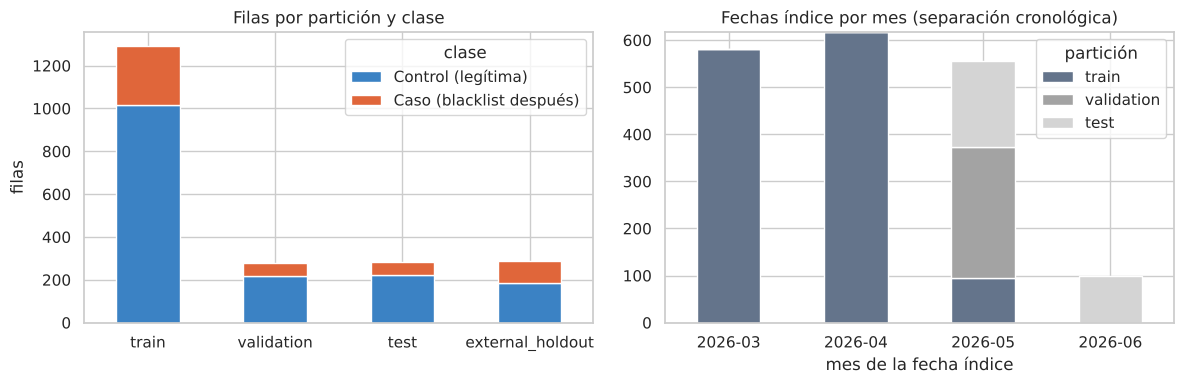

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
conteo = pd.concat([dev, ext]).groupby(["datasetSplit", "target"]).size().unstack()
conteo = conteo.loc[["train", "validation", "test", "external_holdout"]]
conteo.rename(columns=NOMBRES).plot.bar(stacked=True, color=[PALETA[0], PALETA[1]], ax=axes[0], rot=0)
axes[0].legend(title="clase")
axes[0].set_title("Filas por partición y clase")
axes[0].set_xlabel("")
axes[0].set_ylabel("filas")
mensual = dev.groupby([dev.indexAtUtc.dt.strftime("%Y-%m"), "datasetSplit"]).size().unstack(fill_value=0)
mensual[["train", "validation", "test"]].plot.bar(stacked=True, ax=axes[1], rot=0, color=["#64748b", "#a3a3a3", "#d4d4d4"])
axes[1].set_title("Fechas índice por mes (separación cronológica)")
axes[1].legend(title="partición")
axes[1].set_xlabel("mes de la fecha índice")
plt.tight_layout()
plt.savefig(FIG / "eda_01_balance_particiones.png", dpi=160, bbox_inches="tight")
plt.show()

## 3. Estadísticas descriptivas (train)

In [5]:
descr = train[FEATURE_NAMES].describe(percentiles=[.25, .5, .75, .95]).T
descr["asimetria"] = train[FEATURE_NAMES].skew()
descr["pct_ceros"] = (train[FEATURE_NAMES] == 0).mean()
descr.to_csv(MET / "eda_estadisticas_descriptivas.csv")
descr.round(2).sort_values("asimetria", ascending=False).head(15)

,count,mean,std,min,25%,50%,75%,95%,max,asimetria,pct_ceros
outboundCount,1294.0,325.81,3043.13,0.0,3.00,23.00,125.75,1201.00,1.061950e+05,32.71,0.13
selfTransferRatio,1294.0,0.00,0.01,0.0,0.00,0.00,0.00,0.00,1.900000e-01,28.47,0.99
transactionCount,1294.0,606.66,3276.35,0.0,9.25,58.00,322.50,2624.10,1.065970e+05,26.68,0.02
usdtTransferCount,1294.0,608.59,3276.62,0.0,9.25,58.00,325.75,2626.70,1.065970e+05,26.67,0.02
averageDailyTransfers,1294.0,6.76,36.41,0.0,0.10,0.64,3.62,29.19,1.184410e+03,26.67,0.02
transferCount,1294.0,608.59,3276.62,0.0,9.25,58.00,325.75,2626.70,1.065970e+05,26.67,0.02
outboundAmount,1294.0,3540528.27,30773344.43,0.0,1914.37,47090.38,573801.96,10006573.55,9.669624e+08,25.14,0.13
totalAmount,1294.0,7185262.81,61643285.68,0.0,10399.00,151064.78,1421936.35,19790383.44,1.934463e+09,25.06,0.02
usdtAmount,1294.0,7185262.81,61643285.68,0.0,10399.00,151064.78,1421936.35,19790383.44,1.934463e+09,25.06,0.02
inboundAmount,1294.0,3644932.95,30872720.45,0.0,5514.48,90824.55,798149.27,9977450.92,9.675004e+08,24.98,0.03


In [6]:
por_clase = describe_by_class(train).sort_values("razon_caso_control")
por_clase.to_csv(MET / "eda_medianas_por_clase.csv")
por_clase.round(3)

,mediana_control,mediana_caso,razon_caso_control
outboundCount,31.000,4.000,0.129
transferCount,84.000,13.000,0.155
usdtTransferCount,84.000,13.000,0.155
averageDailyTransfers,0.933,0.144,0.155
transactionCount,83.500,13.000,0.156
activeDays,20.000,4.000,0.200
activeDayRatio,0.222,0.044,0.200
observedSpanDays,60.087,12.506,0.208
inboundCount,35.000,8.000,0.229
uniqueCounterparties,18.000,9.000,0.500


**Lectura.** Las variables de conteo y monto tienen **asimetría extrema** (asimetría > 20 en varias): unas pocas
wallets de muy alto volumen dominan la media, por eso se describe con medianas. Las variables TUSD y de autotransferencia son
casi siempre cero (no aportan información en este periodo).

## 4. Gráfico 2 · Distribuciones por clase (escala log)

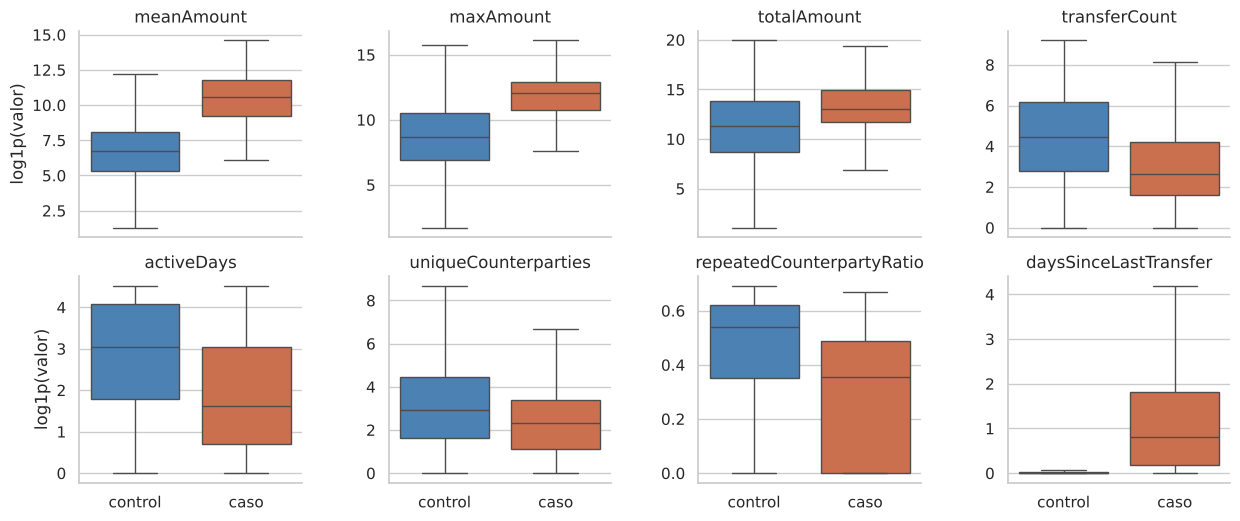

In [7]:
clave = ["meanAmount", "maxAmount", "totalAmount", "transferCount", "activeDays",
         "uniqueCounterparties", "repeatedCounterpartyRatio", "daysSinceLastTransfer"]
largo = train.melt(id_vars="target", value_vars=clave, var_name="variable", value_name="valor")
largo["log1p(valor)"] = log1p_clip(largo["valor"])
largo["clase"] = largo.target.map(NOMBRES)
orden_clases = [NOMBRES[0], NOMBRES[1]]
g = sns.catplot(data=largo, x="clase", y="log1p(valor)", col="variable", col_wrap=4, kind="box",
                order=orden_clases, hue="clase", hue_order=orden_clases, palette=[PALETA[0], PALETA[1]], sharey=False, height=2.8, aspect=1.15,
                showfliers=False, legend=False)
g.set_titles("{col_name}")
g.set_xticklabels(["control", "caso"])
g.set_xlabels("")
plt.savefig(FIG / "eda_02_distribuciones_por_clase.png", dpi=160, bbox_inches="tight")
plt.show()

**Patrones.** Las wallets que luego entran en la blacklist hacen **menos transferencias pero de montos mucho mayores**
(mediana de `meanAmount` ≈ 40 000 USDT frente a ≈ 870 en controles) y tienen menos contrapartes repetidas. Son señales
coherentes con wallets de paso que concentran fondos antes de ser congeladas.

## 5. Gráfico 3 · Poder separador individual de cada variable

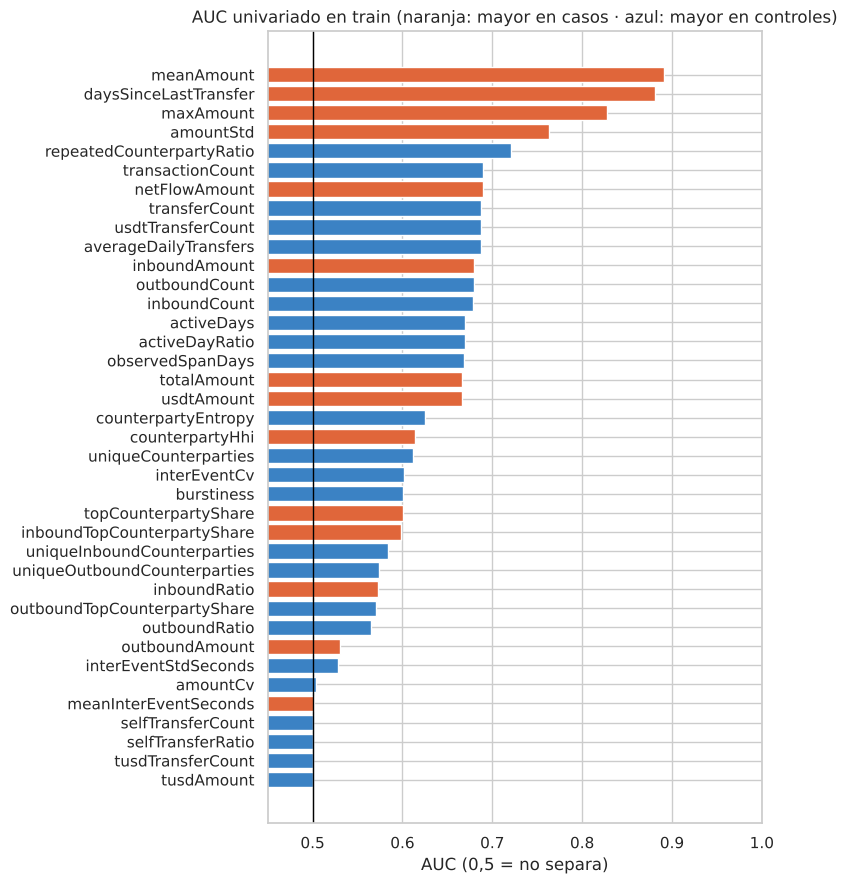

transactionCount             0.690
repeatedCounterpartyRatio    0.720
amountStd                    0.763
maxAmount                    0.828
daysSinceLastTransfer        0.881
meanAmount                   0.892
dtype: float64

In [8]:
from sklearn.metrics import roc_auc_score

auc = pd.Series({f: roc_auc_score(train.target, train[f]) for f in FEATURE_NAMES})
separacion = (auc - 0.5).abs().add(0.5).sort_values()
separacion.to_csv(MET / "eda_auc_univariado.csv", header=["auc_univariado"])
colores = ["#e0663a" if auc[f] > 0.5 else "#3b82c4" for f in separacion.index]
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(separacion.index, separacion.values, color=colores)
ax.axvline(0.5, color="black", lw=1)
ax.set_xlim(0.45, 1)
ax.set_title("AUC univariado en train (naranja: mayor en casos · azul: mayor en controles)")
ax.set_xlabel("AUC (0,5 = no separa)")
plt.tight_layout()
plt.savefig(FIG / "eda_03_auc_univariado.png", dpi=160, bbox_inches="tight")
plt.show()
separacion.tail(6).round(3)

## 6. Gráfico 4 · Correlaciones (Spearman)

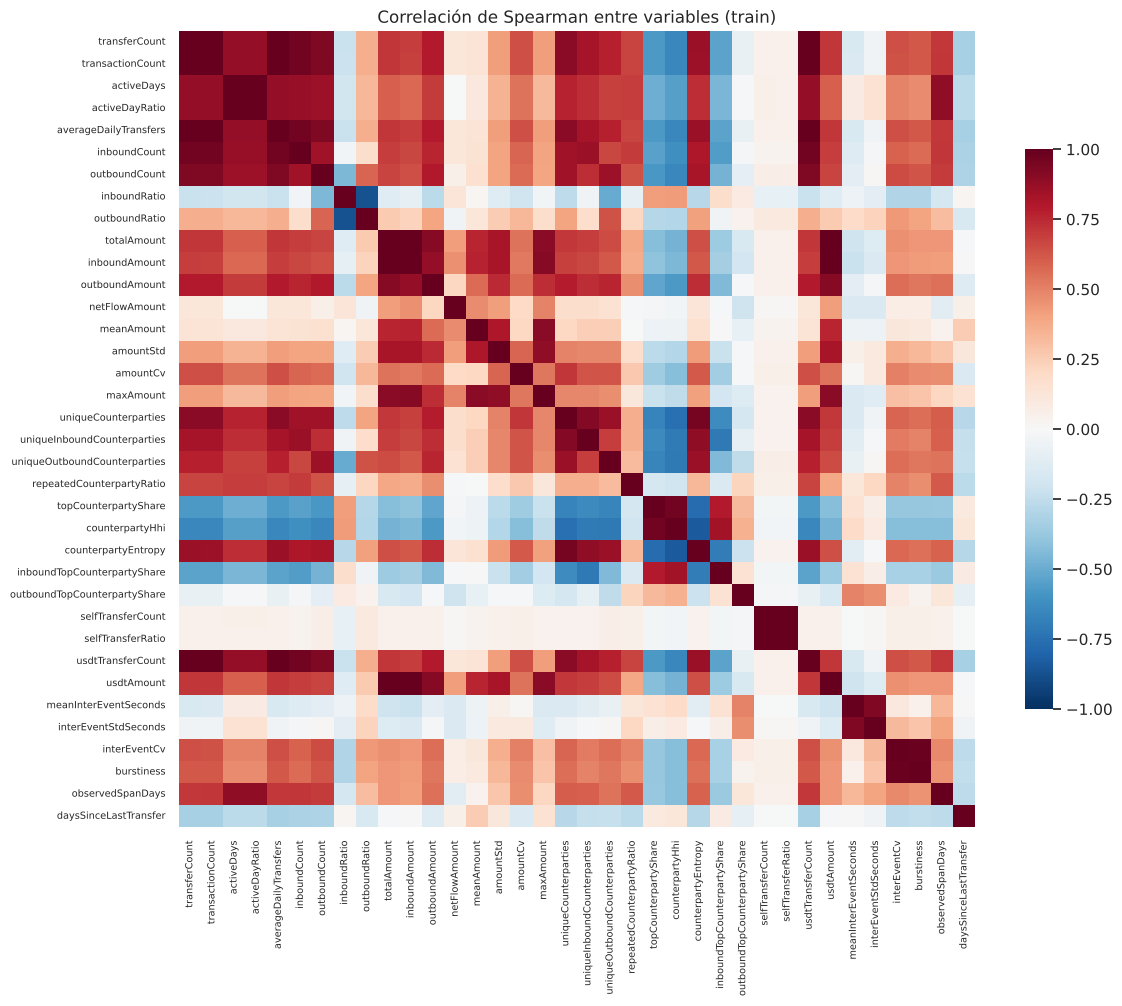

Variables constantes en train: ['tusdTransferCount', 'tusdAmount']
Pares con |rho| >= 0,95: 18


transferCount          averageDailyTransfers    1.000
                       usdtTransferCount        1.000
averageDailyTransfers  usdtTransferCount        1.000
activeDays             activeDayRatio           1.000
totalAmount            usdtAmount               1.000
selfTransferCount      selfTransferRatio        1.000
transferCount          transactionCount         1.000
transactionCount       averageDailyTransfers    1.000
                       usdtTransferCount        1.000
inboundAmount          usdtAmount               0.994
dtype: float64

In [9]:
constantes = [f for f in FEATURE_NAMES if train[f].nunique() <= 1]
variables = [f for f in FEATURE_NAMES if f not in constantes]
corr = train[variables].corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, ax=ax, cbar_kws={"shrink": .7},
            xticklabels=True, yticklabels=True)
ax.set_title("Correlación de Spearman entre variables (train)")
ax.tick_params(labelsize=7)
plt.tight_layout()
plt.savefig(FIG / "eda_04_correlaciones.png", dpi=160, bbox_inches="tight")
plt.show()
pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
pares = pares[pares.abs() >= 0.95].sort_values(ascending=False)
print("Variables constantes en train:", constantes)
print("Pares con |rho| >= 0,95:", len(pares))
pares.head(10).round(3)

**Lectura.** Hay bloques muy redundantes (`transferCount` ≈ `transactionCount` ≈ `usdtTransferCount`;
`totalAmount` = `usdtAmount` cuando no hay TUSD). Para un ensamble de árboles la redundancia no daña la predicción, pero
**reparte la importancia** entre variables equivalentes; por eso la interpretación se hace por familias.

## 7. Gráfico 5 · Valores atípicos (outliers)

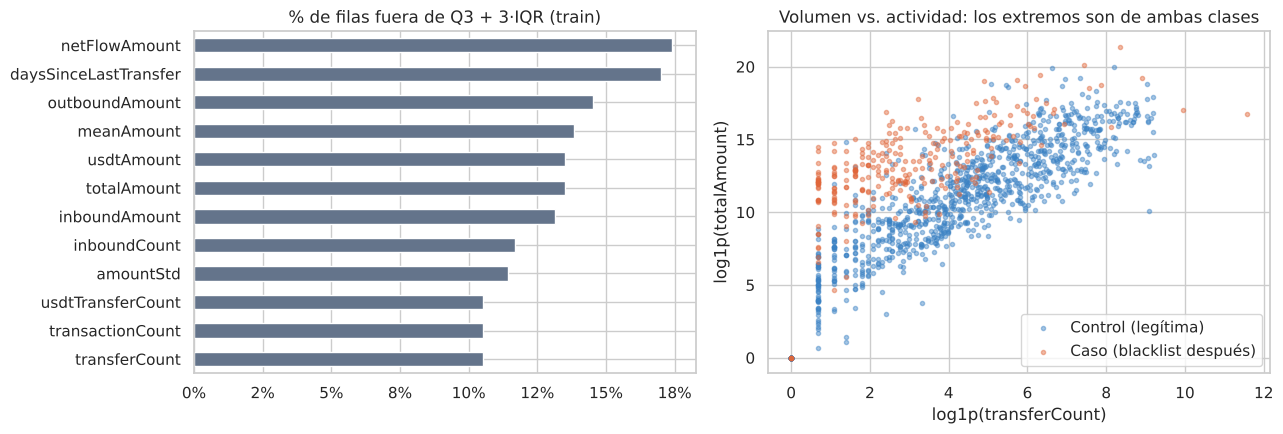

Máximo de transferCount por clase: {0: 9972, 1: 106597}


In [10]:
q1, q3 = train[variables].quantile(.25), train[variables].quantile(.75)
iqr = q3 - q1
atipicos = ((train[variables] > q3 + 3 * iqr) | (train[variables] < q1 - 3 * iqr)).mean().sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
atipicos.head(12).iloc[::-1].plot.barh(ax=axes[0], color="#64748b")
axes[0].set_title("% de filas fuera de Q3 + 3·IQR (train)")
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
for clase in (0, 1):
    sub = train[train.target == clase]
    axes[1].scatter(log1p_clip(sub.transferCount), log1p_clip(sub.totalAmount), s=9, alpha=.45,
                    color=PALETA[clase], label=NOMBRES[clase])
axes[1].set_xlabel("log1p(transferCount)")
axes[1].set_ylabel("log1p(totalAmount)")
axes[1].set_title("Volumen vs. actividad: los extremos son de ambas clases")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIG / "eda_05_outliers.png", dpi=160, bbox_inches="tight")
plt.show()
print("Máximo de transferCount por clase:", train.groupby("target").transferCount.max().to_dict())

**Decisión sobre outliers.** Los valores extremos son **reales** (exchanges, servicios de pago, wallets de paso con
millones de USDT) y aparecen en ambas clases, así que no se eliminan ni se recortan: el gradient boosting con árboles es
invariante a transformaciones monótonas y robusto a extremos. En producción, las wallets con historial demasiado grande para
reconstruirse completo se marcan `NOT_SCORABLE` en lugar de evaluarse con datos truncados.

## 8. Gráfico 6 · Recencia (`daysSinceLastTransfer`) y sesgo de selección

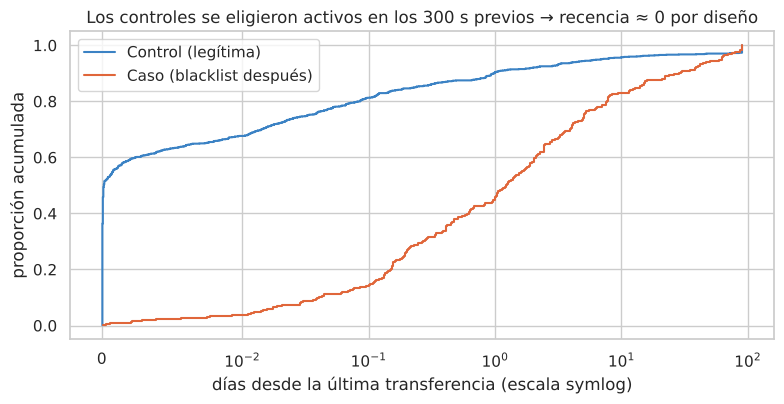

{'Control (legítima)': 0.0, 'Caso (blacklist después)': 1.237}
Controles con recencia < 0,01 días: 67.7%


In [11]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for clase in (0, 1):
    valores = np.sort(train.loc[train.target == clase, "daysSinceLastTransfer"].to_numpy())
    ax.step(valores, np.arange(1, len(valores) + 1) / len(valores), where="post", color=PALETA[clase], label=NOMBRES[clase])
ax.set_xscale("symlog", linthresh=0.01)
ax.set_xlabel("días desde la última transferencia (escala symlog)")
ax.set_ylabel("proporción acumulada")
ax.set_title("Los controles se eligieron activos en los 300 s previos → recencia ≈ 0 por diseño")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "eda_06_recencia_sesgo.png", dpi=160, bbox_inches="tight")
plt.show()
print(train.groupby("target").daysSinceLastTransfer.median().rename(NOMBRES).round(3).to_dict())
print("Controles con recencia < 0,01 días:", f"{(train[train.target == 0].daysSinceLastTransfer < 0.01).mean():.1%}")

**Hallazgo crítico.** `daysSinceLastTransfer` separa casi perfectamente las clases (AUC ≈ 0,88), pero en buena parte
por **cómo se construyó la muestra**: los controles se eligieron entre wallets con una transferencia en los 300 segundos
previos a la fecha índice. La variable mide en parte el diseño y no solo el riesgo. Este sesgo está documentado en el model
card y el ciclo de reentrenamiento v8 usa controles *random-lookback* para corregirlo.

## 9. Gráfico 7 · Wallets sin actividad y variables casi constantes

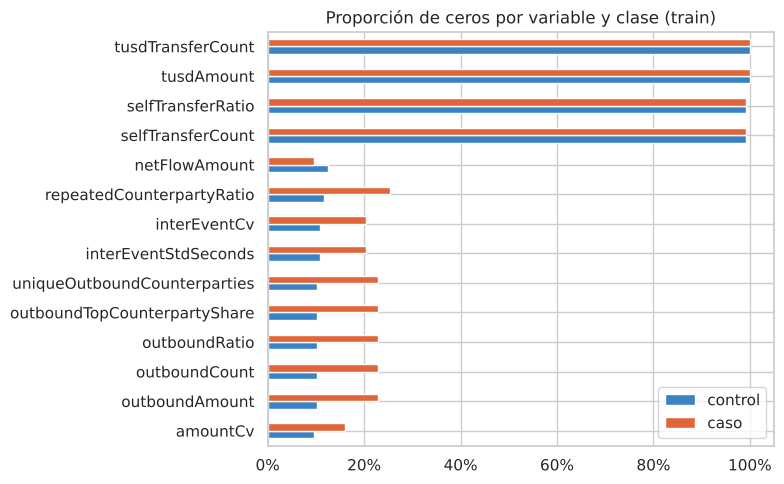

Filas sin transferencias en la ventana: 51 (2.8%)


In [12]:
ceros = (train[FEATURE_NAMES] == 0).groupby(train.target).mean().T
ceros.columns = ["control", "caso"]
ceros = ceros.sort_values("control", ascending=False).head(14)
ax = ceros.iloc[::-1].plot.barh(figsize=(8, 5), color=[PALETA[0], PALETA[1]])
ax.set_title("Proporción de ceros por variable y clase (train)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout()
plt.savefig(FIG / "eda_07_ceros.png", dpi=160, bbox_inches="tight")
plt.show()
sin_actividad = (dev.transferCount == 0)
print(f"Filas sin transferencias en la ventana: {sin_actividad.sum()} ({sin_actividad.mean():.1%})")

## 10. Conclusiones del EDA

1. **Datos completos y limpios:** 0 faltantes, 0 duplicados, 0 cruces de grupos entre particiones (ver notebook 02).
2. **Desbalance moderado por diseño** (≈ 1 riesgosa por cada 3,6 controles); en producción el desbalance real es mucho mayor,
   por eso se usan pesos balanceados, PR-AUC como métrica principal y un análisis de prevalencia.
3. **Asimetría extrema** en montos y conteos → se describen con medianas; el modelo de árboles no requiere transformarlas,
   el baseline lineal sí (`log1p` + estandarización).
4. **Señales más fuertes:** montos promedio/máximos altos, pocas transferencias, menor repetición de contrapartes.
5. **Riesgo de sesgo:** la recencia está inflada por el muestreo de controles; se trata como limitación y se corrige en v8.
6. **Variables constantes** (TUSD, autotransferencias) no aportan en este periodo; se conservan por compatibilidad con la API.